# Setup

In [22]:
import sys

# remove wrong import
if "data" in sys.modules:
    del sys.modules["data"]


PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

print("PROJECT_ROOT =", PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data import prepare

import data
print(data.__file__)

PROJECT_ROOT = /media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/data.py


In [23]:
import sys
from pathlib import Path
from data import prepare
from config import load_config

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

print("PROJECT_ROOT =", PROJECT_ROOT)

sys.path.insert(0, str(PROJECT_ROOT / "src"))


cfg = load_config(PROJECT_ROOT / "configs/config.yaml")

cfg["data"]["root"] = str(
    PROJECT_ROOT.parent.parent / "PTB-XL"
)

print(cfg["data"])

cache, manifest = prepare(cfg)

print("Cache:", cache)
print(manifest["splits"])

FIG_DIR = Path("figures")

(FIG_DIR / "patchtst").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "tft").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "comparison").mkdir(parents=True, exist_ok=True)
(FIG_DIR / "leads").mkdir(parents=True, exist_ok=True)

PROJECT_ROOT = /media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting
{'root': '/media/ehsan/MyFiles3/FraUAS/HIS Project/PTB-XL', 'sampling_rate': 100, 'history': 700, 'horizon': 300, 'synthetic': False, 'start': 0, 'layout': 'time_first'}
Cache: data/study_v3/ee7d4f585e459326
{'train': {'records': 339, 'patients': 300, 'windows': 339}, 'val': {'records': 81, 'patients': 75, 'windows': 81}}


In [24]:
from pathlib import Path
from data import prepare
from data import ECGDataset
from preprocessing import feature_arrays

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"

LEAD_NAMES = [
    "I", "II", "III",
    "aVR", "aVL", "aVF",
    "V1", "V2", "V3",
    "V4", "V5", "V6",
]

def checkpoint_path(mode, run_name):
    return (
        RESULTS_DIR /
        "primary_7s3s_v3" /
        mode /
        "checkpoints" /
        run_name /
        "best.pt"
    )

print(
    checkpoint_path(
        "full",
        "patchtst_P0_F0_full_120e"
    )
)

arrays, names, details = feature_arrays(
    cfg,
    cache,
    "F0",
    splits=("train", "val")
)

dataset = ECGDataset(
    cache,
    cfg,
    "val",
    "P0",
    arrays["val"]
)


sample_idx = 0

sample = dataset[sample_idx]

history = sample["x"].unsqueeze(0)
target = sample["y"]

print(history.shape)
print(target.shape)

/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/results/primary_7s3s_v3/full/checkpoints/patchtst_P0_F0_full_120e/best.pt
torch.Size([1, 700, 12])
torch.Size([300, 12])


In [27]:
import torch
from models import build_model

model = build_model(
    "patchtst",
    static_dim=0,
    horizon=cfg["data"]["horizon"],
    **cfg["model"]
)

checkpoint = torch.load(
    checkpoint_path(
        "full",
        "patchtst_P0_F0_full_120e"
    ),
    map_location="cpu",
    weights_only=False
)

model.load_state_dict(
    checkpoint["model"]
)

model.eval()

print(type(model))

<class 'models.patchtst.PatchTSTForecaster'>


In [28]:
import torch

with torch.inference_mode():
    prediction = model(history).squeeze(0)

print(prediction.shape)

torch.Size([300, 12])


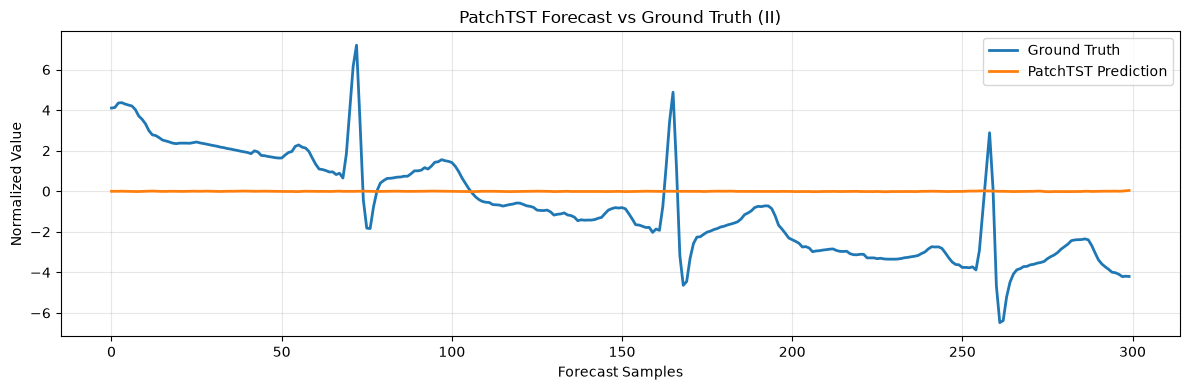

In [29]:
import matplotlib.pyplot as plt

LEAD_NAMES = [
    "I","II","III",
    "aVR","aVL","aVF",
    "V1","V2","V3",
    "V4","V5","V6"
]

lead = 1  # Lead II

plt.figure(figsize=(12,4))

plt.plot(
    target[:, lead].numpy(),
    label="Ground Truth",
    linewidth=2
)

plt.plot(
    prediction[:, lead].numpy(),
    label="PatchTST Prediction",
    linewidth=2
)

plt.title(
    f"PatchTST Forecast vs Ground Truth ({LEAD_NAMES[lead]})"
)

plt.xlabel("Forecast Samples")
plt.ylabel("Normalized Value")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

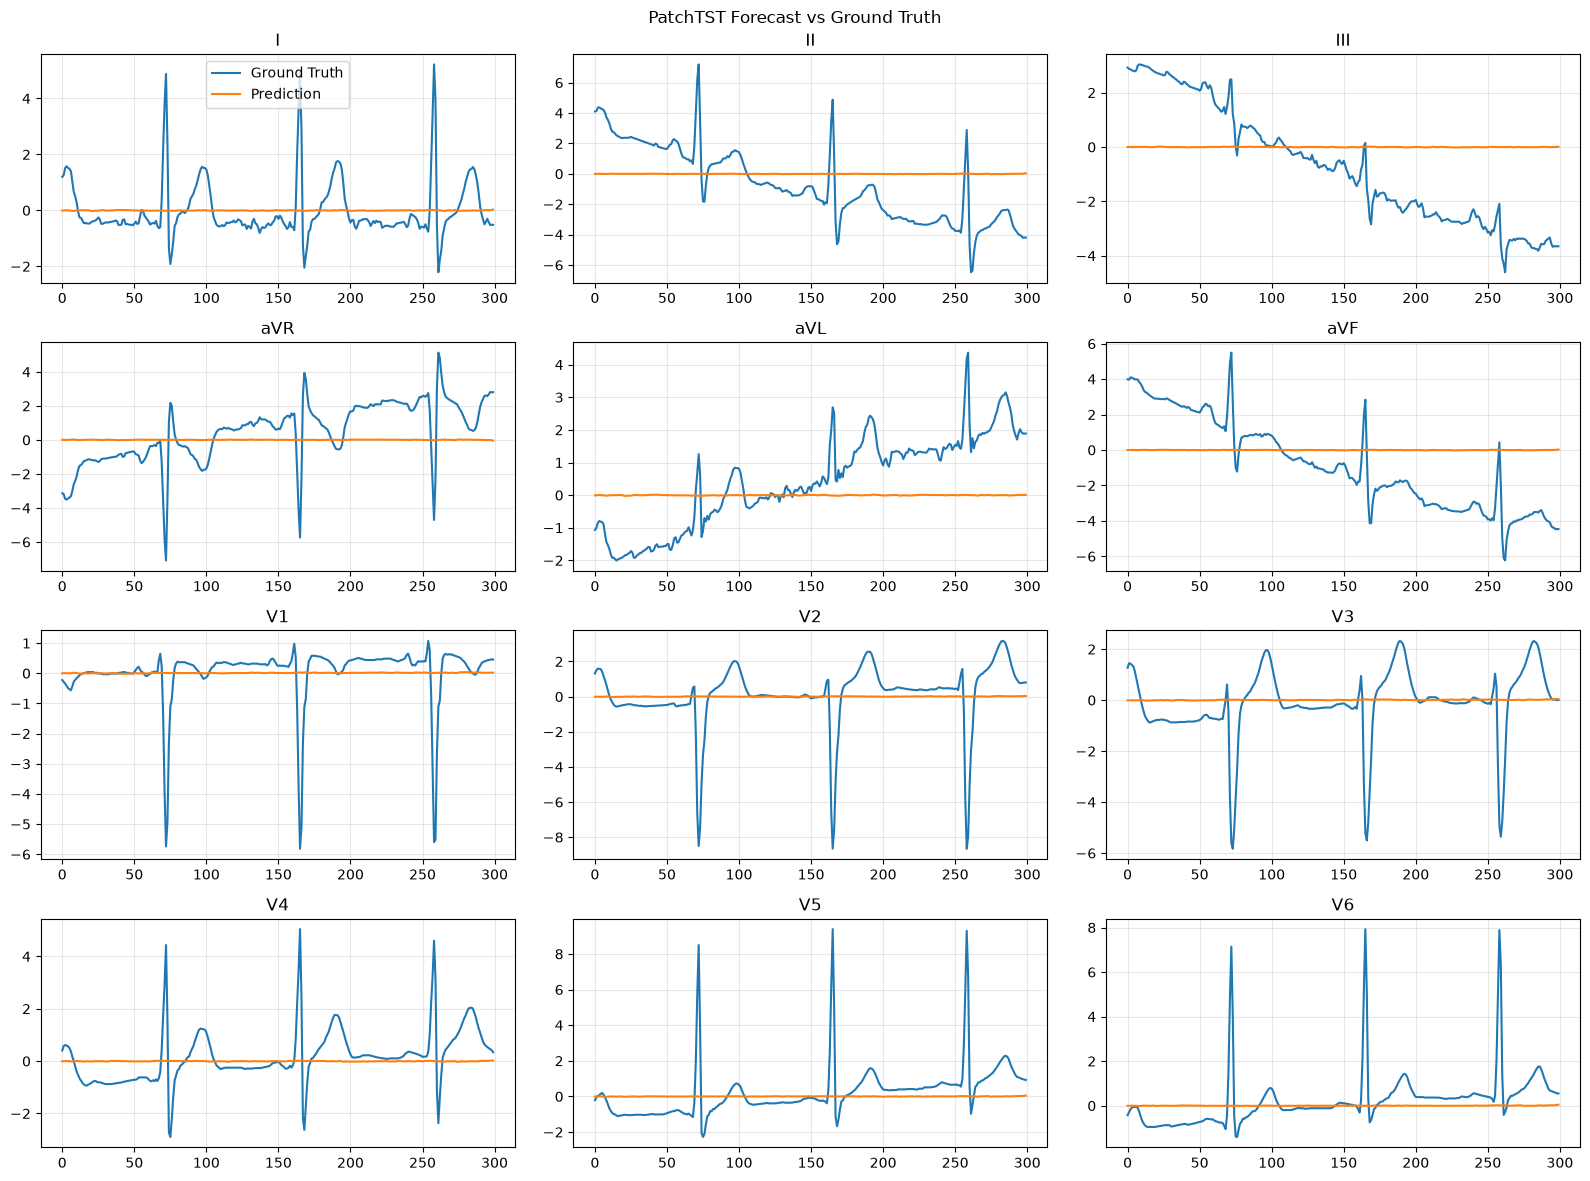

In [30]:
fig, axes = plt.subplots(
    4,
    3,
    figsize=(16,12)
)

axes = axes.flatten()

for lead in range(12):

    ax = axes[lead]

    ax.plot(
        target[:, lead].numpy(),
        label="Ground Truth",
        linewidth=1.5
    )

    ax.plot(
        prediction[:, lead].numpy(),
        label="Prediction",
        linewidth=1.5
    )

    ax.set_title(
        LEAD_NAMES[lead]
    )

    ax.grid(alpha=0.3)

axes[0].legend()

plt.suptitle(
    "PatchTST Forecast vs Ground Truth"
)

plt.tight_layout()

plt.show()

In [31]:
print(prediction.min().item())
print(prediction.max().item())

print(target.min().item())
print(target.max().item())

-0.038625869899988174
0.04637333005666733
-8.656790733337402
9.392390251159668


In [32]:
mae = (
    prediction - target
).abs().mean()

print(mae.item())


1.2196698188781738


In [34]:
for p in (PROJECT_ROOT / "src").rglob("*.py"):
    text = p.read_text(errors="ignore")

    if "patient_macro_mae" in text:
        print(p)

/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/compare.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/evaluate.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/feature_selection.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/metrics.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/report.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/research.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/status.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/visualize.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/train.py


In [35]:
for p in (PROJECT_ROOT / "src").rglob("*.py"):
    text = p.read_text(errors="ignore")

    if "rmse_mV" in text:
        print(p)

/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/compare.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/evaluate.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/metrics.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/report.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/research.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/visualize.py
/media/ehsan/MyFiles3/FraUAS/HIS Project/Code/ptbxl-patient-conditioned-ecg-forecasting/src/train.py
